# Kenya Outbreak Readiness — CRISP-DM workflow

This notebook follows the six CRISP-DM phases to assess whether Kenya’s health facilities are prepared to support outbreak response. It uses the local facility map extract and county boundaries for the analysis that those files support. The downloaded Ministry of Health reports inform the readiness domains and the assessment limitations.

> **Interpretation limit:** the local HOTOSM extract is a facility map, not a facility readiness assessment. The downloaded assessment documents are PDFs, not row-level assessment records. This notebook therefore produces a cleaned facility inventory and county-level mapping/record-completeness indicators. It does not manufacture readiness labels or present map coverage as preparedness.

Run cells from top to bottom. Paths are relative to the project root.

## CRISP-DM overview

| Phase | Work in this notebook | Current status |
|---|---|---|
| 1. Business understanding | Define users, decision, objective, and success measures | Defined |
| 2. Data understanding | Inventory local files, inspect the facility extract, identify limitations | Implemented |
| 3. Data preparation | Normalize fields, preserve missingness, assign facilities to counties | Implemented |
| 4. Modeling | Decide whether the available data support a readiness model | Readiness model gated: no assessment-level rows or outcome labels |
| 5. Evaluation | Check data quality and whether the business objective can be evaluated | Inventory analysis evaluated; readiness model cannot yet be evaluated |
| 6. Deployment | Save reproducible cleaned inventory and county coverage outputs | Implemented for descriptive outputs |

# 1. Business understanding

## 1.1 Decision to support

County health teams need to identify specific facility-level gaps that could limit outbreak response, such as inadequate infection prevention and control (IPC), unreliable water/electricity, insufficient trained staff, weak laboratory capability, or missing emergency equipment.

The Ministry of Health’s 2023 Health Facility Census report covers facility amenities, IPC, workforce, services, equipment, infrastructure, and laboratory readiness. The 2024 QoC-HFA reports cover service availability/readiness and quality systems/workforce. These are the appropriate assessment domains for a readiness analysis.

## 1.2 Project objective

When facility-level assessment records and their codebook are available, produce interpretable facility and county summaries of readiness gaps. A county score from 1 to 10 should be built from explicit assessment indicators and documented weights, then checked against the source assessment’s own definitions or an independent validation source.

For now, use the HOTOSM extract only to describe where facilities are mapped and which descriptive fields have been recorded. It does not measure the readiness domains above.

## 1.3 Success criteria

- Preserve a traceable copy of source data and document every cleaning rule.
- Geographically assign facilities to the 47 county boundaries; report unmatched records.
- Report missingness as “not recorded” rather than treating it as “no capacity.”
- Do not train or evaluate a readiness prediction model until a valid readiness outcome and facility-level assessment features are available.
- Make outputs reproducible from local files without relying on a live dashboard.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "Datasets"
REPORT_DIR = DATA_DIR / "readiness_sources"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "crisp_dm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\TEMP.JOE\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\TEMP.JOE\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\TEMP.JOE\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 807, in start
    self.io_loop.start()
  File "c:\Users\TEMP.JOE\anaconda3\Li

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\TEMP.JOE\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\TEMP.JOE\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\TEMP.JOE\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 807, in start
    self.io_loop.start()
  File "c:\Users\TEMP.JOE\anaconda3\Li

AttributeError: _ARRAY_API not found

Project root: c:\Users\TEMP.JOE\Documents\Outbreak-Readiness-System
Output directory: c:\Users\TEMP.JOE\Documents\Outbreak-Readiness-System\reports\crisp_dm


# 2. Data understanding

## 2.1 Sources present in the project

The HOTOSM GeoJSON contains mapped facilities and OpenStreetMap-style tags. Its `completeness` field describes mapped-tag completeness, not a health-system readiness score. The county GeoJSON supplies the spatial boundary for aggregation.

The downloaded PDFs are high-value reference material, but cannot be joined to facility rows as-is. The World Bank SDI-H 2018 questionnaire and manual describe a separate survey; the actual `.dta` microdata files are not present in this project. Treat the SDI survey as an older alternative dataset requiring catalog access, not as part of the current analysis.

In [2]:
facility_path = DATA_DIR / "kenya.geojson"
county_path = DATA_DIR / "kenya_counties.geojson"

source_documents = [
    "Kenya_Health_Facility_Census_Report_September_2023.pdf",
    "Kenya_QoC_HFA_2024_Service_Availability_Readiness_Report.pdf",
    "Kenya_QoC_HFA_2024_Quality_Systems_Human_Resources_Report.pdf",
    "Kenya_SDI_Health_Survey_2018_Report.pdf",
    "Kenya_SDI_Health_Survey_2018_Questionnaire_Masked.pdf",
    "Kenya_SDI_Health_Survey_2018_Field_Manual.pdf",
    "SDI_Health_Anonymization_Protocol.pdf",
    "SDI_Data_Harmonization_Protocol_February_2021.pdf",
]
source_inventory = pd.DataFrame({
    "file": source_documents,
    "present": [(REPORT_DIR / name).exists() for name in source_documents],
})
source_inventory["path"] = source_inventory["file"].map(lambda name: str(REPORT_DIR / name))
display(source_inventory)

if not facility_path.exists():
    raise FileNotFoundError(f"Facility GeoJSON not found: {facility_path}")
if not county_path.exists():
    raise FileNotFoundError(f"County GeoJSON not found: {county_path}")

facilities_source = gpd.read_file(facility_path)
counties_source = gpd.read_file(county_path)
print("Facility rows/columns:", facilities_source.shape)
print("Facility CRS:", facilities_source.crs)
print("County rows/columns:", counties_source.shape)
print("County CRS:", counties_source.crs)

,file,present,path
0,Kenya_Health_Facility_Census_Report_September_...,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
1,Kenya_QoC_HFA_2024_Service_Availability_Readin...,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
2,Kenya_QoC_HFA_2024_Quality_Systems_Human_Resou...,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
3,Kenya_SDI_Health_Survey_2018_Report.pdf,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
4,Kenya_SDI_Health_Survey_2018_Questionnaire_Mas...,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
5,Kenya_SDI_Health_Survey_2018_Field_Manual.pdf,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
6,SDI_Health_Anonymization_Protocol.pdf,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...
7,SDI_Data_Harmonization_Protocol_February_2021.pdf,True,c:\Users\TEMP.JOE\Documents\Outbreak-Readiness...


Facility rows/columns: (2640, 34)
Facility CRS: EPSG:4326
County rows/columns: (47, 9)
County CRS: EPSG:4326


In [3]:
print("Facility fields:")
print(list(facilities_source.columns))
print("\nCounty fields:")
print(list(counties_source.columns))

county_name_candidates = [c for c in counties_source.columns if str(c).casefold() in {"county", "county_name", "name_1"}]
if not county_name_candidates:
    raise ValueError(f"Could not identify county name field. Found: {list(counties_source.columns)}")
COUNTY_NAME_FIELD = county_name_candidates[0]
print("Using county name field:", COUNTY_NAME_FIELD)

print("\nFacility sample:")
display(facilities_source.head())

Facility fields:
['osm_id', 'osm_type', 'completeness', 'amenity', 'healthcare', 'name', 'operator', 'source', 'speciality', 'operator_type', 'operational_status', 'opening_hours', 'beds', 'staff_doctors', 'staff_nurses', 'health_amenity_type', 'dispensing', 'wheelchair', 'emergency', 'insurance', 'water_source', 'electricity', 'is_in_health_area', 'is_in_health_zone', 'url', 'addr_housenumber', 'addr_street', 'addr_postcode', 'addr_city', 'changeset_id', 'changeset_version', 'changeset_timestamp', 'uuid', 'geometry']

County fields:
['OBJECTID', 'AREA', 'PERIMETER', 'COUNTY3_', 'COUNTY3_ID', 'COUNTY', 'Shape_Leng', 'Shape_Area', 'geometry']
Using county name field: COUNTY

Facility sample:


,osm_id,osm_type,completeness,amenity,healthcare,name,operator,source,speciality,operator_type,operational_status,opening_hours,beds,staff_doctors,staff_nurses,health_amenity_type,dispensing,wheelchair,emergency,insurance,water_source,electricity,is_in_health_area,is_in_health_zone,url,addr_housenumber,addr_street,addr_postcode,addr_city,changeset_id,changeset_version,changeset_timestamp,uuid,geometry
0,474439689,way,21.875,hospital,counselling,Community Health Center,MOH,,,government,,06:00–20:00 daily,,,,,,,,,,,,,,,,,,170715105.0,5.0,2025-08-20 09:49:32+00:00,1e84916be0a9432a8b98d539bc014957,"POLYGON ((35.21691 -1.4435, 35.21701 -1.44349,..."
1,1224725709,way,15.625,hospital,hospital,JOHATTLAS MEDICAL AND DENTAL CENTER,,microsoft/BuildingFootprints,,,,,,,,,,,,,,,,,,,,,,163982188.0,2.0,2025-03-23 11:25:46+00:00,020c4dec61384d65853adb9ee4680784,"POLYGON ((34.45753 -0.53129, 34.45755 -0.53118..."
2,8891997083,node,12.500,*,alternative,Faith Healer,,,,,,,,,,,,,,,,,,,,,,,,107380437.0,1.0,2021-07-04 08:44:18+00:00,4ac9577b8e094463b9436f95117a07c1,POINT (36.8873 -1.25427)
3,2405823297,node,9.375,clinic,,Redeemed Gospel Church Clinic,,,,,,,,,,,,,,,,,,,,,,,,17201651.0,1.0,2013-08-03 09:20:18+00:00,71c100d49785492283c8c7475c7d172d,POINT (36.88785 -1.24688)
4,8415761717,node,28.125,clinic,clinic,Access Afya Baba dogo,,,,private,operational,Mo-Fr 08:00-17:00,2,,,,,,,,,,,,,,,,Nairobi,99124843.0,1.0,2021-02-11 17:31:32+00:00,3ad1a6e7f46649419f72c447d57ad7c7,POINT (36.88652 -1.24433)


In [4]:
# Geometry and attribute-level data quality overview.
attribute_columns = [c for c in facilities_source.columns if c != facilities_source.geometry.name]
profile = pd.DataFrame({
    "dtype": facilities_source[attribute_columns].dtypes.astype(str),
    "missing_count": facilities_source[attribute_columns].isna().sum(),
    "missing_pct": (facilities_source[attribute_columns].isna().mean() * 100).round(1),
    "unique_nonmissing": facilities_source[attribute_columns].nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)
display(profile)

print("Exact duplicate rows:", int(facilities_source.duplicated().sum()))
if {"osm_type", "osm_id"}.issubset(facilities_source.columns):
    print("Duplicate OSM type/id keys:", int(facilities_source.duplicated(["osm_type", "osm_id"]).sum()))
print("Missing geometries:", int(facilities_source.geometry.isna().sum()))
print("Empty geometries:", int(facilities_source.geometry.is_empty.sum()))

,dtype,missing_count,missing_pct,unique_nonmissing
osm_id,int64,0,0.0,2640
osm_type,str,0,0.0,2
completeness,float64,0,0.0,14
amenity,str,0,0.0,12
healthcare,str,0,0.0,26
name,str,0,0.0,2321
operator,str,0,0.0,229
source,str,0,0.0,19
speciality,str,0,0.0,65
operator_type,str,0,0.0,29


Exact duplicate rows: 0
Duplicate OSM type/id keys: 0
Missing geometries: 0
Empty geometries: 0


In [5]:
# Inspect the fields that might look readiness-related. Their presence or absence
# in the map does not certify operational capacity.
possible_capacity_fields = [
    "beds", "staff_doctors", "staff_nurses", "emergency", "water_source",
    "electricity", "operational_status", "opening_hours", "wheelchair",
]
field_summary = pd.DataFrame({
    "field": possible_capacity_fields,
    "in_extract": [c in facilities_source.columns for c in possible_capacity_fields],
    "recorded_rows": [int(facilities_source[c].notna().sum()) if c in facilities_source else 0 for c in possible_capacity_fields],
})
if len(facilities_source):
    field_summary["recorded_pct"] = (field_summary["recorded_rows"] / len(facilities_source) * 100).round(1)
display(field_summary)

,field,in_extract,recorded_rows,recorded_pct
0,beds,True,2640,100.0
1,staff_doctors,True,2640,100.0
2,staff_nurses,True,2640,100.0
3,emergency,True,2640,100.0
4,water_source,True,2640,100.0
5,electricity,True,2640,100.0
6,operational_status,True,2640,100.0
7,opening_hours,True,2640,100.0
8,wheelchair,True,2640,100.0


## 2.2 Initial findings and risks

Missing values indicate that a map attribute was not recorded. They do not establish that beds, staff, water, electricity, or emergency services are absent at the real facility. Likewise, a missing facility in the extract is not proof that a facility does not exist.

The downloaded census and QoC-HFA reports are much better aligned to readiness, but their PDF format does not provide row-level records for model training. The official census report points readers to the [Kenya Health Facility Assessment results dashboard](https://cema.shinyapps.io/kenya-hfa-app/), which presents facility and county readiness results. The current project does not contain a machine-readable export from that dashboard.

# 3. Data preparation

We create a separate analysis copy, preserve the source, standardize blank text, normalize a small set of known spelling variants, convert selected numeric/date fields, and keep unknowns unknown. We do not impute missing readiness capacity or delete facilities because of incomplete records.

In [6]:
facilities = facilities_source.copy()
counties = counties_source.copy()

# Harmonize GeoJSON property names for analysis.
facilities.columns = [str(c).strip() for c in facilities.columns]
counties.columns = [str(c).strip() for c in counties.columns]
COUNTY_NAME_FIELD = next(c for c in counties.columns if c.casefold() in {"county", "county_name", "name_1"})

# Normalize empty and whitespace-only text values, excluding geometry.
text_columns = [
    c for c in facilities.columns
    if c != facilities.geometry.name
    and (pd.api.types.is_object_dtype(facilities[c]) or pd.api.types.is_string_dtype(facilities[c]))
]
for col in text_columns:
    facilities[col] = facilities[col].astype("string").str.strip()
    facilities[col] = facilities[col].replace(r"^\s*$", pd.NA, regex=True)

# Identifiers should be labels, never quantities.
for col in ["osm_id", "osm_type", "uuid", "changeset_id"]:
    if col in facilities.columns:
        facilities[col] = facilities[col].astype("string")

# Standardize only known tag spelling/label variants.
tag_aliases = {
    "counseling": "counselling",
    "councelling": "counselling",
    "couselling": "counselling",
    "birthing_centre": "birthing_center",
    "pharmaccy": "pharmacy",
}
def normalize_tag(value):
    if pd.isna(value):
        return value
    tokens = [token.strip().casefold() for token in str(value).split(";")]
    return ";".join(tag_aliases.get(token, token) for token in tokens)
for col in ["amenity", "healthcare"]:
    if col in facilities.columns:
        facilities[col] = facilities[col].map(normalize_tag).astype("string")

if "beds" in facilities.columns:
    beds = pd.to_numeric(facilities["beds"], errors="coerce")
    facilities["beds_invalid_negative"] = beds.lt(0).fillna(False)
    facilities["beds"] = beds.mask(beds.lt(0))
if "completeness" in facilities.columns:
    facilities["completeness"] = pd.to_numeric(facilities["completeness"], errors="coerce")
if "changeset_version" in facilities.columns:
    facilities["changeset_version"] = pd.to_numeric(facilities["changeset_version"], errors="coerce")
if "changeset_timestamp" in facilities.columns:
    facilities["changeset_timestamp"] = pd.to_datetime(facilities["changeset_timestamp"], errors="coerce", utc=True)

print("Rows retained:", len(facilities), "of", len(facilities_source))

Rows retained: 2640 of 2640


In [7]:
# Review the recoding of the non-specific amenity marker; do not silently infer
# meaning for unmatched values.
if {"amenity", "healthcare"}.issubset(facilities.columns):
    star_rows = facilities[facilities["amenity"].eq("*")][["osm_type", "osm_id", "amenity", "healthcare", "name"]].copy()
    confirmed = facilities["amenity"].eq("*") & facilities["healthcare"].eq("alternative")
    facilities.loc[confirmed, "amenity"] = "alternative"
    facilities.loc[facilities["amenity"].eq("*"), "amenity"] = "unclassified (*)"
    print("Original '*' rows:", len(star_rows))
    print("Confirmed as alternative from healthcare tag:", int(confirmed.sum()))
    display(star_rows.head(20))

Original '*' rows: 19
Confirmed as alternative from healthcare tag: 19


,osm_type,osm_id,amenity,healthcare,name
2,node,8891997083,*,alternative,Faith Healer
28,node,8891997079,*,alternative,Herbalist-Baba Senje
64,node,8891997092,*,alternative,Traditional Healer
183,node,8891997085,*,alternative,Traditional Healer
454,node,8891997086,*,alternative,Faith healer
759,node,8891997078,*,alternative,Traditional Healer
927,node,8891997076,*,alternative,Faith healer
1189,node,8891997073,*,alternative,Dr. Samwel (Herbalist)
1448,node,8891997087,*,alternative,Traditional Healer
1597,node,8891997081,*,alternative,Faith healer


In [8]:
# Standardize county labels and spatially assign facilities.
counties["county"] = counties[COUNTY_NAME_FIELD].astype("string").str.strip()
counties["county"] = counties["county"].replace({
    "Keiyo-Marakwet": "Elgeyo-Marakwet",
    "Tharaka": "Tharaka-Nithi",
})
if facilities.crs is None or counties.crs is None:
    raise ValueError("Facility and county layers both need a defined coordinate reference system.")
if facilities.crs != counties.crs:
    counties = counties.to_crs(facilities.crs)

county_polygons = counties[["county", counties.geometry.name]].copy()
county_polygons = county_polygons.rename_geometry("county_geometry")
facility_geo = facilities[facilities.geometry.notna() & ~facilities.geometry.is_empty].copy()
facility_geo = facility_geo.set_geometry(facility_geo.geometry.name)

facility_county = gpd.sjoin(
    facility_geo,
    county_polygons.set_geometry("county_geometry"),
    how="left",
    predicate="within",
).drop(columns=["index_right"], errors="ignore")

print("Facilities with geometry:", len(facility_geo))
print("Facilities assigned to a county:", int(facility_county["county"].notna().sum()))
print("Facilities outside/unmatched to boundaries:", int(facility_county["county"].isna().sum()))
print("Unique counties in boundary file:", county_polygons["county"].nunique())

Facilities with geometry: 2640
Facilities assigned to a county: 2635
Facilities outside/unmatched to boundaries: 5
Unique counties in boundary file: 47


## 3.1 Prepared data-quality outputs

Missingness is summarized as the fraction of records with a missing field. A high recorded rate in HOTOSM only means the map has a value for that tag; confirm the facility information independently before operational use.

In [9]:
prepared_attributes = [c for c in facilities.columns if c != facilities.geometry.name]
missingness = pd.DataFrame({
    "missing_count": facilities[prepared_attributes].isna().sum(),
    "missing_pct": (facilities[prepared_attributes].isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
display(missingness)

key_counts = {
    "source_rows": len(facilities_source),
    "prepared_rows": len(facilities),
    "exact_duplicate_rows": int(facilities.duplicated().sum()),
    "rows_with_geometry": int((facilities.geometry.notna() & ~facilities.geometry.is_empty).sum()),
    "rows_assigned_county": int(facility_county["county"].notna().sum()),
    "counties_in_boundary_file": int(county_polygons["county"].nunique()),
}
display(pd.Series(key_counts, name="count"))

,missing_count,missing_pct
staff_doctors,2640,100.00
staff_nurses,2640,100.00
is_in_health_area,2640,100.00
is_in_health_zone,2640,100.00
url,2637,99.89
insurance,2632,99.70
water_source,2623,99.36
health_amenity_type,2622,99.32
addr_housenumber,2583,97.84
wheelchair,2583,97.84


source_rows                  2640
prepared_rows                2640
exact_duplicate_rows            0
rows_with_geometry           2640
rows_assigned_county         2635
counties_in_boundary_file      47
Name: count, dtype: int64

# 4. Modeling

## 4.1 Model selection decision

A supervised regression or classification model needs a defensible target (for example, an independently assessed facility readiness score) and predictors measured for the same facility and time. Neither is available in the local files. A dummy regressor or neural network trained on a score we invent from facility counts would only reproduce that invented score; it would not learn outbreak readiness.

Accordingly, this phase does **not** train a readiness model. The valid next modeling step is to obtain the facility-level 2023 census or 2024 QoC-HFA export, its codebook, sampling/assessment metadata, and a documented readiness outcome. Then choose either:

1. a transparent domain score from the assessment indicators (preferred if the task is score construction), or
2. a supervised model only if there is a separate observed outcome to predict (for example, subsequent assessment or response performance).

Do not use input indicators that are mathematically part of a score as predictors of that same score and then report the result as predictive performance; that is target leakage.

In [10]:
# Readiness model gate. This file is intentionally not assumed to exist because
# no machine-readable HFA/HOTC assessment export is currently in this project.
assessment_candidates = [
    DATA_DIR / "kenya_hfa_facility_assessment.csv",
    DATA_DIR / "kenya_qoc_hfa_2024_facility_assessment.csv",
]
assessment_files_present = [p for p in assessment_candidates if p.exists()]

if not assessment_files_present:
    print("Readiness model not trained.")
    print("Reason: facility-level assessment rows and a validated readiness outcome are not present.")
    print("Expected source: an authorized export from the Kenya Health Facility Assessment results dashboard.")
else:
    print("Assessment file(s) found:", [str(p) for p in assessment_files_present])
    print("Next step: inspect the codebook and confirm the target and predictor definitions before modeling.")

Readiness model not trained.
Reason: facility-level assessment rows and a validated readiness outcome are not present.
Expected source: an authorized export from the Kenya Health Facility Assessment results dashboard.


## 4.2 Descriptive county coverage analysis

The following county aggregation is an operational data-inventory output, not a readiness model. Counts depend on the completeness of the map extract and do not account for population size, facility level, catchment area, or service capacity.

In [11]:
county_counts = (
    facility_county.dropna(subset=["county"])
    .groupby("county", dropna=False)
    .size()
    .rename("mapped_facilities")
    .reset_index()
)
county_summary = county_polygons[["county", "county_geometry"]].copy()
county_summary = county_summary.merge(county_counts, on="county", how="left")
county_summary["mapped_facilities"] = county_summary["mapped_facilities"].fillna(0).astype(int)

# County area supports an optional map-density description, not population access.
area = counties[["county", counties.geometry.name]].to_crs("EPSG:6933")
area["area_km2"] = area.geometry.area / 1_000_000
county_summary = county_summary.merge(area[["county", "area_km2"]], on="county", how="left")
county_summary["mapped_facilities_per_km2"] = county_summary["mapped_facilities"] / county_summary["area_km2"]
county_summary = county_summary.sort_values("mapped_facilities", ascending=False).reset_index(drop=True)

display(county_summary[["county", "mapped_facilities", "area_km2", "mapped_facilities_per_km2"]])

,county,mapped_facilities,area_km2,mapped_facilities_per_km2
0,Nairobi,1199,704.864295,1.701037
1,Kisumu,152,2674.641120,0.056830
2,Wajir,113,56706.740994,0.001993
3,Kiambu,93,2573.710190,0.036135
4,Baringo,87,10796.205352,0.008058
5,Nakuru,76,7445.581355,0.010207
6,Kilifi,65,12500.007118,0.005200
7,Kitui,63,30557.178372,0.002062
8,Turkana,56,69745.972189,0.000803
9,Mombasa,53,226.481954,0.234014


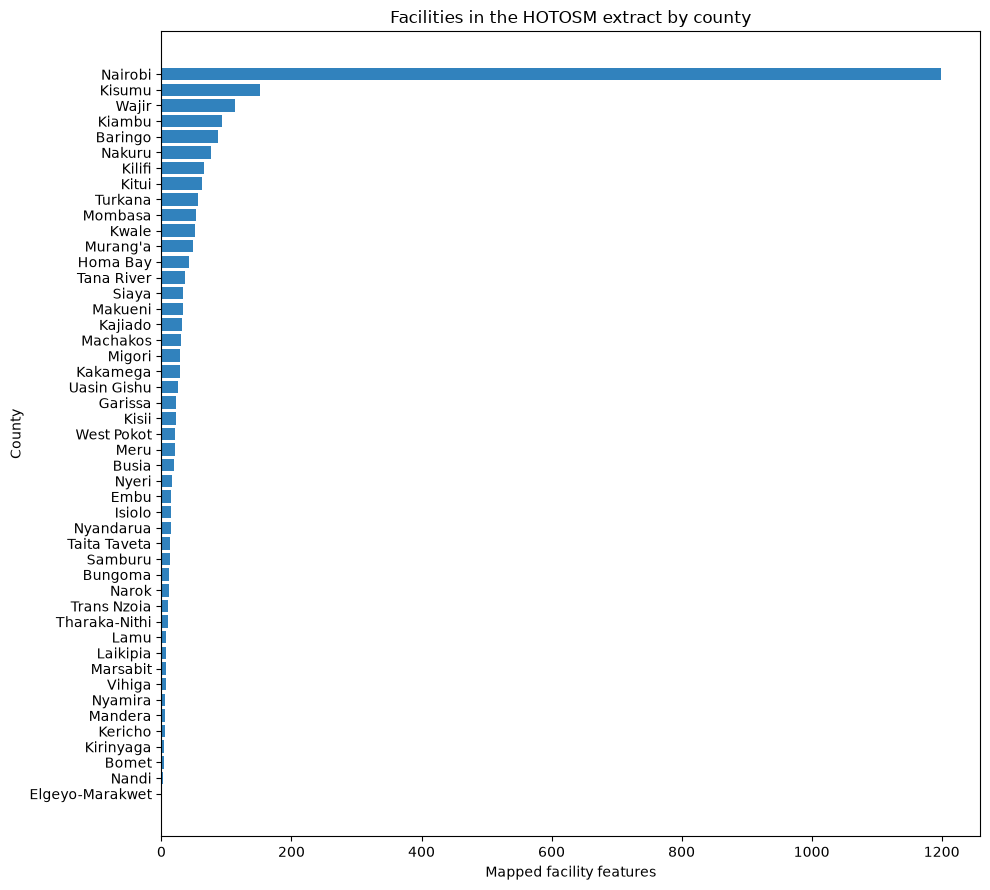

,records
healthcare tag,
not recorded,1231
hospital,506
counselling,292
clinic,280
pharmacy,226
laboratory,25
alternative,22
dentist,17
psychotherapist,16


In [12]:
plt.figure(figsize=(10, 9))
plot_data = county_summary.sort_values("mapped_facilities", ascending=True)
plt.barh(plot_data["county"], plot_data["mapped_facilities"], color="#3182bd")
plt.xlabel("Mapped facility features")
plt.ylabel("County")
plt.title("Facilities in the HOTOSM extract by county")
plt.tight_layout()
plt.show()

if "healthcare" in facilities.columns:
    display(facilities["healthcare"].fillna("not recorded").value_counts().head(20).rename_axis("healthcare tag").to_frame("records"))

# 5. Evaluation

## 5.1 What can be evaluated now

The data preparation can be checked using row retention, duplicate keys, valid geometries, county assignment rate, and missingness. Those checks assess the reliability of the facility inventory and its tags.

## 5.2 What cannot be evaluated now

There is no observed facility or county outbreak-readiness outcome in the local files, so predictive metrics such as MAE, RMSE, precision/recall, or calibration would be meaningless for readiness. The facility count baseline would only benchmark mapped counts. The HOTOSM `completeness` attribute measures mapped attributes, not readiness.

For an eventual readiness score, evaluate construct validity against the source assessment definitions, review indicator direction and weights with public-health stakeholders, and compare county/facility findings with an independent assessment or operational measure. Use a held-out time period or independent facilities for a predictive model.

In [13]:
# Compact acceptance checks for the descriptive workflow.
checks = pd.Series({
    "county_layer_has_47_unique_counties": county_polygons["county"].nunique() == 47,
    "prepared_retains_all_source_rows": len(facilities) == len(facilities_source),
    "county_assignment_rate_reported": facility_county["county"].notna().sum() <= len(facility_county),
    "readiness_model_not_misrepresented": not bool(assessment_files_present),
})
display(checks.to_frame("passed"))

,passed
county_layer_has_47_unique_counties,True
prepared_retains_all_source_rows,True
county_assignment_rate_reported,True
readiness_model_not_misrepresented,True


# 6. Deployment

## 6.1 Deployable outputs now

The notebook exports the cleaned facility inventory and county mapped-facility summary for review. These files support data stewardship and coverage review; they must not be labeled as county preparedness scores.

## 6.2 Operational deployment after assessment data arrive

1. Obtain an authorized facility-level export from the official [assessment dashboard](https://cema.shinyapps.io/kenya-hfa-app/) or the data custodian. The [2023 census report](https://www.health.go.ke/sites/default/files/2024-01/Kenya%20Health%20Facility%20Census%20Report%20September%202023.pdf) documents the assessment domains and dashboard; the [2024 QoC-HFA service availability/readiness report](https://health.go.ke/sites/default/files/2026-06/Main%20Report%20-%20SARA%2021.10.2025.pdf) and [quality systems/workforce report](https://countdown2030.org/wp-content/uploads/2025/10/Main-Report-HR-21.10.2025.pdf) provide newer assessment context.
2. Store the export, codebook, access date, coverage period, and licensing/usage conditions under `Datasets/`.
3. Validate facility identifiers and county names; preserve assessment date/version so the score can be refreshed.
4. Define a transparent readiness score and missing-data policy with domain experts before model fitting.
5. Publish score, coverage, source date, uncertainty/data completeness, and actionable gaps together. Do not display a single score without its assessment year and completeness context.

In [14]:
# Export descriptive outputs. The raw input files remain unchanged.
cleaned_output = OUTPUT_DIR / "kenya_facilities_cleaned_inventory.geojson"
county_output = OUTPUT_DIR / "kenya_county_mapped_facility_coverage.csv"
missingness_output = OUTPUT_DIR / "kenya_facility_field_missingness.csv"

facilities.to_file(cleaned_output, driver="GeoJSON")
county_summary[["county", "mapped_facilities", "area_km2", "mapped_facilities_per_km2"]].to_csv(county_output, index=False)
missingness.to_csv(missingness_output, index=True)

print("Saved descriptive outputs:")
for path in [cleaned_output, county_output, missingness_output]:
    print("-", path)

Saved descriptive outputs:
- c:\Users\TEMP.JOE\Documents\Outbreak-Readiness-System\reports\crisp_dm\kenya_facilities_cleaned_inventory.geojson
- c:\Users\TEMP.JOE\Documents\Outbreak-Readiness-System\reports\crisp_dm\kenya_county_mapped_facility_coverage.csv
- c:\Users\TEMP.JOE\Documents\Outbreak-Readiness-System\reports\crisp_dm\kenya_facility_field_missingness.csv


## CRISP-DM conclusion

This run completes the available data understanding, preparation, descriptive county analysis, evaluation checks, and export steps. It does not produce an outbreak-readiness prediction because the machine-readable assessment records and a validated readiness target are missing. The next concrete step is to obtain and add those assessment records; the official dashboard is referenced by the census report and is the appropriate source to check for a downloadable facility table.

### Sources and data documentation

- Ministry of Health, *Kenya Health Facility Census Report, September 2023*: [report PDF](https://www.health.go.ke/sites/default/files/2024-01/Kenya%20Health%20Facility%20Census%20Report%20September%202023.pdf) and [results dashboard](https://cema.shinyapps.io/kenya-hfa-app/).
- Ministry of Health, *Kenya Quality of Care Health Facility Assessment 2024: Service Availability and Readiness*: [report PDF](https://health.go.ke/sites/default/files/2026-06/Main%20Report%20-%20SARA%2021.10.2025.pdf).
- *Kenya Quality of Care Health Facility Assessment 2024: Quality Systems and Human Resources*: [report PDF](https://countdown2030.org/wp-content/uploads/2025/10/Main-Report-HR-21.10.2025.pdf).
- HOTOSM Kenya health-facilities extract already stored at `Datasets/kenya.geojson` and `Datasets/kenya.csv`; see [Humanitarian Data Exchange source](https://data.humdata.org/dataset/hotosm_ken_health_facilities).
- The SDI-H 2018 catalog and its microdata access note are documented in `Datasets/readiness_sources/README.md`.